# Fraunhofer Diffraction -- Circular Aperture

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch04/ch04-09.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** run the setup cell below first. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

In [ ]:
# --- Setup: run this cell first.  It does nothing outside Google Colab. ---
import sys, os, importlib.util, urllib.request
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # interactive matplotlib (%matplotlib widget) needs ipympl and Colab's custom widget manager
    if importlib.util.find_spec("ipympl") is None:
        get_ipython().run_line_magic("pip", "install -q ipympl")
        print("ipympl installed. Colab will restart the runtime once; when it has, run this cell again.")
        get_ipython().kernel.do_shutdown(restart=True)
    from google.colab import output
    output.enable_custom_widget_manager()

## Import libraries

In [1]:
from scipy.special import j1 # Bessel function of the first kind order 1
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, PowerNorm, LogNorm
from matplotlib.colors import LightSource

## Define parameters

In [2]:
# --- Parameters ---
L1 = 2 * 10**6       # Distance to screen in microns
wavelength1 = 0.632  # Wavelength in microns
a_rho1 = 40          # radius of circular aperture in microns

# --- Generate Aperture Data ---
numpoints = 512
x1ap = np.linspace(-400, 400, num=numpoints)
y1ap = x1ap
X1ap, Y1ap = np.meshgrid(x1ap, y1ap)
aperture1_3d = np.where(X1ap**2 + Y1ap**2 <= (a_rho1)**2, 1.0, 0.0)

# --- Generate Screen/Diffraction Data ---
# Screen range is large (1e5), but physics is in the center
x1 = np.linspace(-1e5, 1e5, num=numpoints)
y1 = x1
X1, Y1 = np.meshgrid(x1, y1)
Q1 = np.sqrt(X1**2 + Y1**2)

# Analytical Airy Disk expression
arg = (2 * np.pi / wavelength1 * a_rho1 / L1 * Q1)
intensity1_2d = (2 * j1(arg) / arg)**2
intensity1_2d = np.nan_to_num(intensity1_2d, nan=1.0) # Handle center limit

## Plot

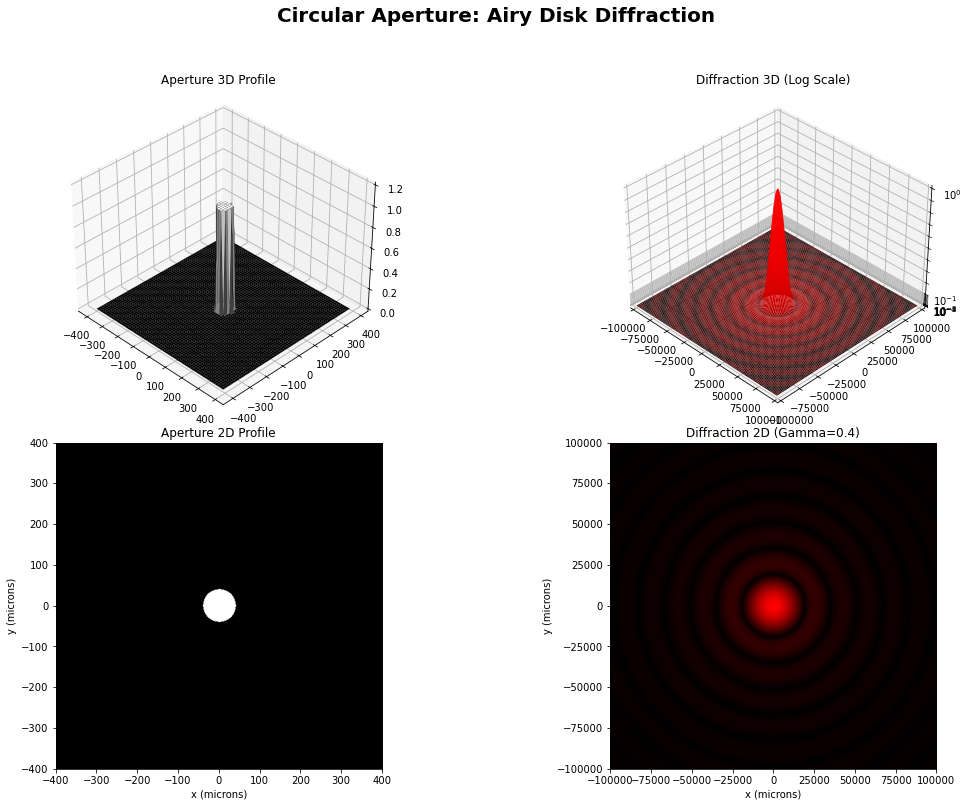

In [4]:
# --- Plotting Configuration ---
plt.rcParams.update({'font.size': 14, 'font.family': 'sans-serif'})
colors = [(0, 0, 0), (1, 0, 0)] # Black to Red
laser_cmap = LinearSegmentedColormap.from_list("laser_red", colors)
ls = LightSource(azdeg=315, altdeg=45)

fig = plt.figure(figsize=(16, 12))
fig.suptitle("Circular Aperture: Airy Disk Diffraction", fontsize=20, fontweight='bold', y=0.96)

# --- 1. Aperture 3D (Top Left) ---
ax1 = fig.add_subplot(2, 2, 1, projection='3d')
stride_ap = 8
ax1.plot_surface(X1ap[::stride_ap, ::stride_ap], 
                 Y1ap[::stride_ap, ::stride_ap], 
                 aperture1_3d[::stride_ap, ::stride_ap], 
                 rstride=1, cstride=1, cmap='gray', edgecolor='black', 
                 linewidth=0.1, shade=True, lightsource=ls, antialiased=True)
ax1.set_title("Aperture 3D Profile")
ax1.set_zlim(0, 1.2)
ax1.view_init(elev=35, azim=-45)

# --- 2. Diffraction 3D (Top Right) - LOG SCALE & CLIPPED ---
ax2 = fig.add_subplot(2, 2, 2, projection='3d')

# ZOOM/CLIP LOGIC: Focus on the center where rings exist
zoom_val = 10e4  # Adjust this to see more/fewer rings
vmin_val = 1e-5
mask = (np.abs(X1) <= zoom_val) & (np.abs(Y1) <= zoom_val)

# Slicing the data to prevent the "spike" look
# We use a smaller stride here to keep the rings smooth
st = 4
X1_z = X1[mask].reshape(len(np.where(np.abs(x1)<=zoom_val)[0]), -1)[::st, ::st]
Y1_z = Y1[mask].reshape(len(np.where(np.abs(y1)<=zoom_val)[0]), -1)[::st, ::st]
Z1_z = intensity1_2d[mask].reshape(len(np.where(np.abs(x1)<=zoom_val)[0]), -1)[::st, ::st]

ax2.plot_surface(X1_z, Y1_z, Z1_z + vmin_val, 
                 rstride=1, cstride=1, cmap=laser_cmap, 
                 norm=LogNorm(vmin=vmin_val, vmax=1.0),
                 linewidth=0, antialiased=True, shade=True)

ax2.set_zscale('log')
ax2.set_zlim(vmin_val, 1)
ax2.set_xlim(-zoom_val, zoom_val)
ax2.set_ylim(-zoom_val, zoom_val)
ax2.set_box_aspect((1, 1, 0.7))
ax2.set_title("Diffraction 3D (Log Scale)")
ax2.view_init(elev=35, azim=-45)

# --- 3. Aperture 2D (Bottom Left) ---
ax3 = fig.add_subplot(2, 2, 3)
ax3.imshow(aperture1_3d, extent=[-400, 400, -400, 400], cmap='gray', aspect='equal')
ax3.set_title("Aperture 2D Profile")
ax3.set_xlabel("x (microns)")
ax3.set_ylabel("y (microns)")

# --- 4. Diffraction 2D (Bottom Right) - GAMMA CORRECTED ---
ax4 = fig.add_subplot(2, 2, 4)
ax4.imshow(intensity1_2d, extent=[-1e5, 1e5, -1e5, 1e5], cmap=laser_cmap, 
           norm=PowerNorm(gamma=0.4), aspect='equal')
ax4.set_title("Diffraction 2D (Gamma=0.4)")
ax4.set_xlabel("x (microns)")
ax4.set_ylabel("y (microns)")
# Match the zoom of the 3D plot
ax4.set_xlim(-zoom_val, zoom_val)
ax4.set_ylim(-zoom_val, zoom_val)

plt.tight_layout(rect=[0, 0.03, 1, 0.93])
plt.show()

## Animation

In [ ]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, PowerNorm, LogNorm
from matplotlib.colors import LightSource
from scipy.special import j1
import ipywidgets as widgets

# --- 1. Global Setup ---
plt.rcParams.update({'font.size': 10})
colors = [(0, 0, 0), (1, 0, 0)] 
laser_cmap = LinearSegmentedColormap.from_list("laser_red", colors)
ls = LightSource(azdeg=315, altdeg=45)

L1 = 2 * 10**6 
numpoints = 300 # Increased for better resolution of rings
diffraction_zoom = 2.5e4 # Local zoom to make rings visible in 3D
vmin_val = 1e-5

# Coordinate Grids
# Aperture Grid
x1ap = np.linspace(-400, 400, num=numpoints)
X1ap, Y1ap = np.meshgrid(x1ap, x1ap)

# Diffraction Grid (Centered on the zoom area to maximize resolution)
x1scr = np.linspace(-diffraction_zoom, diffraction_zoom, num=numpoints)
X1scr, Y1scr = np.meshgrid(x1scr, x1scr)
Q1scr = np.sqrt(X1scr**2 + Y1scr**2)

# --- 2. Initialize Figure ---
fig = plt.figure(figsize=(12, 9))
if hasattr(fig.canvas, 'header_visible'):
    fig.canvas.header_visible = False

ax1 = fig.add_subplot(2, 2, 1, projection='3d')
ax2 = fig.add_subplot(2, 2, 2, projection='3d')
ax3 = fig.add_subplot(2, 2, 3)
ax4 = fig.add_subplot(2, 2, 4)

# Persistent Images
im3 = ax3.imshow(np.zeros((numpoints, numpoints)), extent=[-400, 400, -400, 400], 
                 cmap='gray', vmin=0, vmax=1, origin='lower')

im4 = ax4.imshow(np.zeros((numpoints, numpoints)), extent=[-diffraction_zoom, diffraction_zoom, -diffraction_zoom, diffraction_zoom], 
                 cmap=laser_cmap, norm=PowerNorm(gamma=0.4, vmin=0, vmax=1), origin='lower')

surf1 = [None]
surf2 = [None]

def update(a_rho=40.0, wavelength=0.632):
    # Physics Calculation
    aperture = np.where(X1ap**2 + Y1ap**2 <= a_rho**2, 1.0, 0.0)
    
    # Airy Pattern Calculation
    # Note: Using the diffraction-specific grid Q1scr
    arg = (2 * np.pi / wavelength * a_rho / L1 * Q1scr)
    intensity = np.ones_like(arg)
    safe = arg != 0
    intensity[safe] = (2 * j1(arg[safe]) / arg[safe])**2
    
    # Update 2D
    im3.set_data(aperture)
    im4.set_data(intensity)
    im4.set_norm(PowerNorm(gamma=0.4, vmin=0, vmax=1.0)) 
    
    # Update 3D Surfaces
    if surf1[0]: surf1[0].remove()
    if surf2[0]: surf2[0].remove()
    
    # Use different strides for speed/quality balance
    s_ap = 10
    s_diff = 4 # More points for the diffraction surface to show rings
    
    surf1[0] = ax1.plot_surface(X1ap[::s_ap, ::s_ap], Y1ap[::s_ap, ::s_ap], aperture[::s_ap, ::s_ap],
                                 cmap='gray', shade=True, lightsource=ls, antialiased=False)
    
    surf2[0] = ax2.plot_surface(X1scr[::s_diff, ::s_diff], Y1scr[::s_diff, ::s_diff], intensity[::s_diff, ::s_diff] + 1e-6,
                                 cmap=laser_cmap, norm=LogNorm(vmin=vmin_val, vmax=1.0),
                                 shade=True, antialiased=False)
    
    # Formatting
    ax1.set_zlim(0, 1.2)
    ax1.set_title("Aperture Profile (3D)")
    
    ax2.set_zscale('log')
    ax2.set_zlim(vmin_val, 1)
    ax2.set_xlim(-diffraction_zoom, diffraction_zoom)
    ax2.set_ylim(-diffraction_zoom, diffraction_zoom)
    ax2.set_box_aspect((1, 1, 0.7))
    ax2.set_title("Diffraction Intensity (Log 3D)")
    
    ax3.set_title("Aperture (2D)")
    ax4.set_title("Diffraction (2D)")
    
    fig.canvas.draw_idle()

widgets.interact(update, 
                 a_rho=widgets.FloatSlider(value=40, min=10, max=100, step=2, description='Radius (μm)'),
                 wavelength=widgets.FloatSlider(value=0.632, min=0.4, max=0.8, step=0.01, description='λ (μm)'))

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch04/ch04-09_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch04/ch04-09.html) (direct link: [ch04-09_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch04/ch04-09_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.